In [1]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.fft import rfft, rfftfreq

from sklearn.model_selection import GroupShuffleSplit, LeaveOneGroupOut, cross_val_score
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                              f1_score, balanced_accuracy_score, log_loss,
                              roc_curve, auc, precision_recall_curve, average_precision_score)
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler, label_binarize, LabelEncoder
from sklearn.calibration import calibration_curve
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance
from sklearn.utils.class_weight import compute_sample_weight
import joblib

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('Set2')

RANDOM_STATE = 42
SAMPLING_RATE_HZ = 56.3  
WINDOW_SIZE = 100
STEP_SIZE = 50
PURITY_THRESHOLD = 0.8
SENTINEL_LOW, SENTINEL_HIGH = -32768, 32767
CORR_THRESHOLD = 0.95

EXPECTED_N_IMU_COLS = 36
EXPECTED_N_EMG_COLS = 2

np.random.seed(RANDOM_STATE)

In [2]:
DATA_PATH = "../hugadb_cleaned.parquet"

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Файл не найден: {DATA_PATH}\n"
        "Проверьте, что ноутбук запущен из той же папки, или поправьте DATA_PATH"
    )

print("Загрузка данных...")
df = pd.read_parquet(DATA_PATH)
print(f"Данные загружены. Размер: {df.shape}")
df.head()

Загрузка данных...
Данные загружены. Размер: (1137279, 42)


,Unnamed: 0,accelerometer_right_foot_x,accelerometer_right_foot_y,accelerometer_right_foot_z,gyroscope_right_foot_x,gyroscope_right_foot_y,gyroscope_right_foot_z,accelerometer_right_shin_x,accelerometer_right_shin_y,accelerometer_right_shin_z,...,accelerometer_left_thigh_y,accelerometer_left_thigh_z,gyroscope_left_thigh_x,gyroscope_left_thigh_y,gyroscope_left_thigh_z,EMG_right,EMG_left,activity,subject_id,session_id
0,0,-7868,-1336,13400,-28,26,-24,-14920,-240,-6800,...,2088,16016,26,-3,9,120,129,sitting,1,0
1,1,-7956,-1384,13468,-20,28,-22,-14824,-216,-6928,...,2224,16184,20,-3,7,120,128,sitting,1,0
2,2,-7892,-1348,13492,-18,24,-26,-14816,-144,-6808,...,2168,16216,21,-7,9,120,129,sitting,1,0
3,3,-7856,-1352,13504,-16,23,-21,-14984,-56,-7200,...,2184,16048,20,-3,4,121,128,sitting,1,0
4,4,-7896,-1356,13440,-13,26,-21,-14944,-280,-6920,...,2032,16040,21,-9,7,121,128,sitting,1,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1137279 entries, 0 to 1137278
Data columns (total 42 columns):
 #   Column                       Non-Null Count    Dtype 
---  ------                       --------------    ----- 
 0   Unnamed: 0                   1137279 non-null  int64 
 1   accelerometer_right_foot_x   1137279 non-null  int64 
 2   accelerometer_right_foot_y   1137279 non-null  int64 
 3   accelerometer_right_foot_z   1137279 non-null  int64 
 4   gyroscope_right_foot_x       1137279 non-null  int64 
 5   gyroscope_right_foot_y       1137279 non-null  int64 
 6   gyroscope_right_foot_z       1137279 non-null  int64 
 7   accelerometer_right_shin_x   1137279 non-null  int64 
 8   accelerometer_right_shin_y   1137279 non-null  int64 
 9   accelerometer_right_shin_z   1137279 non-null  int64 
 10  gyroscope_right_shin_x       1137279 non-null  int64 
 11  gyroscope_right_shin_y       1137279 non-null  int64 
 12  gyroscope_right_shin_z       1137279 non-null  int64 
 1

In [4]:
df.describe()

,Unnamed: 0,accelerometer_right_foot_x,accelerometer_right_foot_y,accelerometer_right_foot_z,gyroscope_right_foot_x,gyroscope_right_foot_y,gyroscope_right_foot_z,accelerometer_right_shin_x,accelerometer_right_shin_y,accelerometer_right_shin_z,...,accelerometer_left_thigh_x,accelerometer_left_thigh_y,accelerometer_left_thigh_z,gyroscope_left_thigh_x,gyroscope_left_thigh_y,gyroscope_left_thigh_z,EMG_right,EMG_left,subject_id,session_id
count,1.137279e+06,1.137279e+06,1.137279e+06,1.137279e+06,1.137279e+06,1.137279e+06,1.137279e+06,1.137279e+06,1.137279e+06,1.137279e+06,...,1.137279e+06,1.137279e+06,1.137279e+06,1.137279e+06,1.137279e+06,1.137279e+06,1.137279e+06,1.137279e+06,1.137279e+06,1.137279e+06
mean,2.085694e+03,-1.110215e+04,-5.093655e+03,1.200353e+04,-2.745808e+02,-2.294360e+02,-1.783301e+02,-1.571618e+04,-4.545324e+02,-5.065570e+03,...,-1.519942e+04,1.095298e+03,1.640779e+03,1.529842e+02,-7.461319e+01,2.174918e+02,1.253868e+02,1.261660e+02,9.536643e+00,1.045832e+01
std,1.766475e+03,9.141796e+03,8.150134e+03,8.534907e+03,5.560050e+03,1.092163e+04,8.484232e+03,6.873450e+03,6.032234e+03,7.916587e+03,...,7.483863e+03,5.733431e+03,9.759412e+03,5.616908e+03,7.142156e+03,2.459386e+03,2.057253e+01,2.182400e+01,4.937896e+00,6.705786e+00
min,0.000000e+00,-3.276800e+04,-3.276800e+04,-3.276800e+04,-3.276800e+04,-3.276800e+04,-3.276800e+04,-3.276800e+04,-3.276800e+04,-3.276800e+04,...,-3.276800e+04,-3.276800e+04,-3.276800e+04,-3.276800e+04,-3.276800e+04,-3.276800e+04,0.000000e+00,0.000000e+00,1.000000e+00,0.000000e+00
25%,7.950000e+02,-1.166800e+04,-7.912000e+03,1.110800e+04,-2.790000e+02,-1.480000e+02,-2.240000e+02,-1.670000e+04,-2.624000e+03,-7.552000e+03,...,-1.713200e+04,-1.120000e+03,-2.992000e+03,-3.050000e+02,-4.440000e+02,-1.200000e+02,1.210000e+02,1.220000e+02,6.000000e+00,5.000000e+00
50%,1.662000e+03,-9.288000e+03,-4.564000e+03,1.252400e+04,-1.400000e+01,4.000000e+01,-3.200000e+01,-1.588000e+04,2.640000e+02,-3.552000e+03,...,-1.600800e+04,1.048000e+03,-3.600000e+02,3.500000e+01,-2.000000e+00,2.100000e+01,1.260000e+02,1.270000e+02,9.000000e+00,1.000000e+01
75%,2.818000e+03,-7.424000e+03,-2.872000e+03,1.400000e+04,1.930000e+02,5.410000e+02,5.160000e+02,-1.438000e+04,2.064000e+03,-1.480000e+03,...,-1.323200e+04,2.776000e+03,5.640000e+03,6.150000e+02,1.062000e+03,3.230000e+02,1.290000e+02,1.310000e+02,1.400000e+01,1.600000e+01
max,1.247100e+04,3.276700e+04,3.276700e+04,3.276700e+04,3.276700e+04,3.276700e+04,3.276700e+04,3.276700e+04,3.276700e+04,3.276700e+04,...,3.276700e+04,3.276700e+04,3.276700e+04,3.276700e+04,3.276700e+04,3.276700e+04,2.540000e+02,2.540000e+02,1.800000e+01,2.700000e+01


In [5]:
df.nunique()

Unnamed: 0                     12472
accelerometer_right_foot_x     15098
accelerometer_right_foot_y     16256
accelerometer_right_foot_z     16208
gyroscope_right_foot_x         50849
gyroscope_right_foot_y         61781
gyroscope_right_foot_z         60742
accelerometer_right_shin_x     13355
accelerometer_right_shin_y     14726
accelerometer_right_shin_z     15301
gyroscope_right_shin_x         55033
gyroscope_right_shin_y         62001
gyroscope_right_shin_z         42227
accelerometer_right_thigh_x    13072
accelerometer_right_thigh_y    14727
accelerometer_right_thigh_z    15840
gyroscope_right_thigh_x        48765
gyroscope_right_thigh_y        53707
gyroscope_right_thigh_z        30248
accelerometer_left_foot_x      14706
accelerometer_left_foot_y      16083
accelerometer_left_foot_z      15935
gyroscope_left_foot_x          50644
gyroscope_left_foot_y          61265
gyroscope_left_foot_z          60110
accelerometer_left_shin_x      13199
accelerometer_left_shin_y      14583
a

## EDA

In [6]:
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])
    print("Колонка 'Unnamed: 0' удалена")

METADATA_COLS = ['activity', 'subject_id', 'session_id']
assert set(METADATA_COLS) <= set(df.columns), "Проверьте наличие activity/subject_id/session_id"

meta_na = df[METADATA_COLS].isna().sum()
print("Пропуски в метаданных:")
print(meta_na)
if meta_na.sum() > 0:
    print(f"\n⚠ {meta_na.sum()} строк с пропуском в метаданных — без явного удаления "
          f"groupby() тихо исключит их из windowing, без единого warning.")
    n_before = len(df)
    df = df.dropna(subset=METADATA_COLS).reset_index(drop=True)
    df[['subject_id', 'session_id']] = df[['subject_id', 'session_id']].astype(int)  # NaN upcasts int->float
    print(f"Удалены явно: {n_before} -> {len(df)}")

sensor_cols_tmp = [c for c in df.columns if c not in METADATA_COLS]
print(f"\nПропуски в сенсорных колонках: {df[sensor_cols_tmp].isna().sum().sum()} "
      f"(обрабатываются интерполяцией по группам, раздел 8)")

dup_mask = df.duplicated(keep=False)
n_dup_rows = dup_mask.sum()
print(f"\nСтрок в полных дубликатах: {n_dup_rows}")
if n_dup_rows > 0:
    print("По (subject_id, session_id):")
    print(df.loc[dup_mask].groupby(['subject_id', 'session_id']).size())
    n_before = len(df)
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"Удалены: {n_before} -> {len(df)}")

Колонка 'Unnamed: 0' удалена
Пропуски в метаданных:
activity      0
subject_id    0
session_id    0
dtype: int64

Пропуски в сенсорных колонках: 0 (обрабатываются интерполяцией по группам, раздел 8)

Строк в полных дубликатах: 0


In [7]:
SENSOR_COLS = [c for c in df.columns if c not in METADATA_COLS]
EMG_COLS = [c for c in SENSOR_COLS if 'emg' in c.lower()]
IMU_COLS = [c for c in SENSOR_COLS if c not in EMG_COLS]

assert set(METADATA_COLS + SENSOR_COLS) == set(df.columns)

print(f"Сенсорных колонок: {len(SENSOR_COLS)} (IMU: {len(IMU_COLS)}, EMG: {len(EMG_COLS)})")
print(f"Участников: {df['subject_id'].nunique()}, сессий: {df['session_id'].nunique()}")

if len(IMU_COLS) != EXPECTED_N_IMU_COLS or len(EMG_COLS) != EXPECTED_N_EMG_COLS:
    print(f"\n⚠ Ожидалось {EXPECTED_N_IMU_COLS} IMU / {EXPECTED_N_EMG_COLS} EMG, "
          f"получено {len(IMU_COLS)} / {len(EMG_COLS)}. Проверьте df.columns вручную, "
          f"либо это другая версия/подмножество датчиков, либо эвристика 'emg' in name "
          f"не находит ваши EMG-колонки по имени.")

Сенсорных колонок: 38 (IMU: 36, EMG: 2)
Участников: 18, сессий: 28


## Activity Distribution

                   count  percent
activity                         
walking           314966    27.69
standing          222345    19.55
going_up          135127    11.88
going_down        119819    10.54
up_by_elevator     89144     7.84
sitting            82574     7.26
down_by_elevator   68762     6.05
running            65917     5.80
standing_up        20506     1.80
sitting_down       18119     1.59


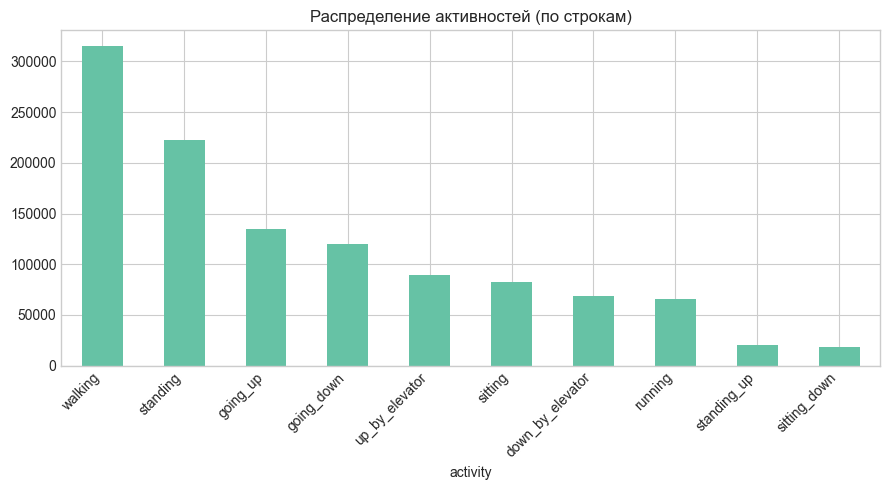

In [8]:
counts = df['activity'].value_counts()
pct = df['activity'].value_counts(normalize=True) * 100
print(pd.DataFrame({'count': counts, 'percent': pct.round(2)}))

fig, ax = plt.subplots(figsize=(9, 5))
counts.plot(kind='bar', ax=ax)
ax.set_title('Распределение активностей (по строкам)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## IMU-сентинелы и EMG-насыщение

In [ ]:
low_count = (df[IMU_COLS] == SENTINEL_LOW).sum().sum()
high_count = (df[IMU_COLS] == SENTINEL_HIGH).sum().sum()
rows_affected = df[IMU_COLS].isin([SENTINEL_LOW, SENTINEL_HIGH]).any(axis=1).sum()
print(f"IMU: -32768: {low_count}, 32767: {high_count}, строк затронуто: "
      f"{rows_affected} ({rows_affected/len(df):.2%})")

if EMG_COLS:
    print("\n--- EMG: насыщение (границы 0 и 255) ---")
    print(df[EMG_COLS].isin([0, 255]).sum())
    emg_rows = df[EMG_COLS].isin([0, 255]).any(axis=1).sum()
    print(f"Строк с EMG на границе: {emg_rows} ({emg_rows/len(df):.2%})")
    print("Примечание: для EMG 0/255 не всегда 'ошибка' (может быть подлинным сигналом "
          "покоя мышцы), но это не 'чистый' сигнал")

IMU: -32768: 601821, 32767: 245977, строк затронуто: 340298 (29.92%)

--- EMG: насыщение (границы 0 и 255) ---
EMG_right    4238
EMG_left     5802
dtype: int64
Строк с EMG на границе: 9876 (0.87%)
Примечание: для EMG 0/255 не всегда 'ошибка' (может быть подлинным сигналом покоя мышцы), но в любом случае это не 'чистый' сигнал, и его нужно учитывать при очистке/фильтрации.


## Interpolation and fallback

In [10]:
def interpolate_and_impute(frame, cols, group_cols=('subject_id', 'session_id'), verbose=True):
    """Линейная интерполяция NaN по группам (subject_id, session_id) — не пересекает
    границы записей. Если после интерполяции NaN остались (группа убита целиком по
    этой колонке) — fallback на медиану по всему датасету, с явным логом."""
    frame = frame.copy()
    frame[cols] = (
        frame.groupby(list(group_cols), group_keys=False)[cols]
             .apply(lambda g: g.interpolate(method='linear', limit_direction='both'))
    )
    remaining_na = frame[cols].isna().sum()
    remaining_na = remaining_na[remaining_na > 0]
    if verbose and len(remaining_na):
        print("NaN после интерполяции внутри группы (группа убита целиком):")
        print(remaining_na)
    for col in remaining_na.index:
        fallback_value = frame[col].median()
        if verbose:
            print(f"  -> '{col}': {remaining_na[col]} строк заполнены медианой ({fallback_value:.1f})")
        frame[col] = frame[col].fillna(fallback_value)
    return frame

df[IMU_COLS] = df[IMU_COLS].replace([SENTINEL_LOW, SENTINEL_HIGH], np.nan)
df = interpolate_and_impute(df, IMU_COLS)
print(f"\nNaN среди IMU после исправления: {df[IMU_COLS].isna().sum().sum()}")

NaN после интерполяции внутри группы (группа убита целиком):
accelerometer_right_foot_z    1144
dtype: int64
  -> 'accelerometer_right_foot_z': 1144 строк заполнены медианой (12484.0)

NaN среди IMU после исправления: 0


In [11]:
def scan_out_of_range(frame, cols, lo=SENTINEL_LOW, hi=SENTINEL_HIGH):
    return {c: int(((frame[c] < lo) | (frame[c] > hi)).sum())
            for c in cols if ((frame[c] < lo) | (frame[c] > hi)).any()}

bad_report = scan_out_of_range(df, IMU_COLS)
print("Значения вне диапазона int16 после очистки сентинелов:", bad_report or "не найдено")

if bad_report:
    for col in bad_report:
        bad_mask = (df[col] < SENTINEL_LOW) | (df[col] > SENTINEL_HIGH)
        df.loc[bad_mask, col] = np.nan
    df = interpolate_and_impute(df, list(bad_report.keys()))  # та же функция -> fallback гарантирован
    print(f"Исправлено. NaN среди IMU: {df[IMU_COLS].isna().sum().sum()}")

assert df[IMU_COLS].isna().sum().sum() == 0, "НЕОЖИДАННО: NaN остались перед windowing!"

Значения вне диапазона int16 после очистки сентинелов: {'accelerometer_left_shin_x': 1}
Исправлено. NaN среди IMU: 0


## Оптимизация типов данных

In [12]:
df[SENSOR_COLS] = df[SENSOR_COLS].astype('float32')
print(df.dtypes.value_counts())
print(f"Память: {df.memory_usage(deep=True).sum() / 1024**2:.1f} MB")

float32    38
int64       2
object      1
Name: count, dtype: int64
Память: 253.7 MB


## Cтруктура сегментов активности

In [13]:
seg_id = (df.groupby(['subject_id', 'session_id'])['activity']
            .transform(lambda s: (s != s.shift()).cumsum()))
seg_id.name = 'segment'  
seg_lengths = (df.groupby(['subject_id', 'session_id', seg_id])['activity']
                 .agg(['first', 'size']).rename(columns={'first': 'activity', 'size': 'length'}))

print("Статистика длины сегментов (в отсчётах):")
print(seg_lengths['length'].describe())
print(f"\nСегментов короче WINDOW_SIZE={WINDOW_SIZE}: "
      f"{(seg_lengths['length'] < WINDOW_SIZE).sum()} из {len(seg_lengths)}")
print("\nПо активностям — медианная длина сегмента:")
print(seg_lengths.groupby('activity')['length'].median().sort_values())

Статистика длины сегментов (в отсчётах):
count    3821.000000
mean      297.639100
std       316.892709
min        11.000000
25%       136.000000
50%       208.000000
75%       330.000000
max      5727.000000
Name: length, dtype: float64

Сегментов короче WINDOW_SIZE=100: 664 из 3821

По активностям — медианная длина сегмента:
activity
sitting_down         65.0
standing_up          69.0
standing            162.0
sitting             200.0
walking             205.0
going_down          252.0
going_up            309.0
down_by_elevator    691.0
up_by_elevator      737.0
running             794.0
Name: length, dtype: float64


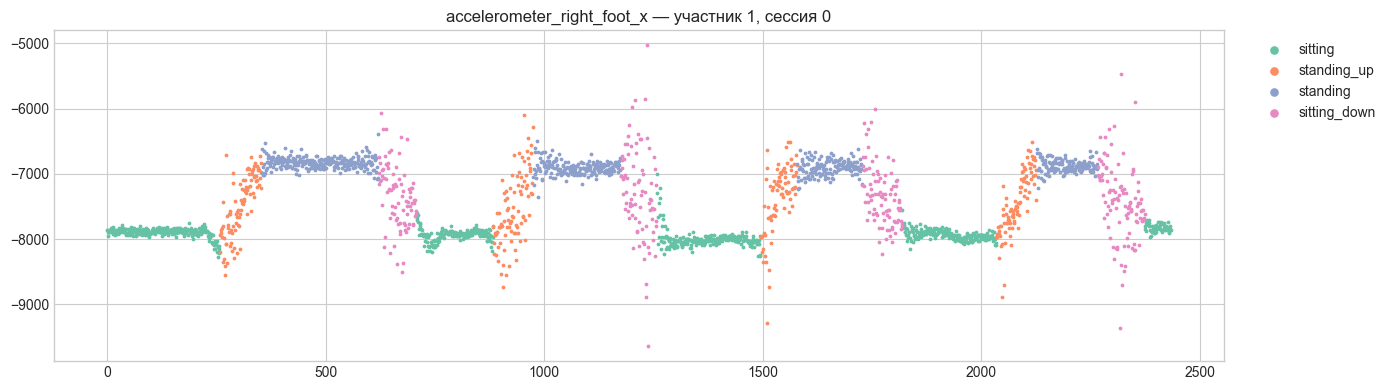

In [14]:
example_col = IMU_COLS[0]
subj = df['subject_id'].iloc[0]
sess = df.loc[df['subject_id'] == subj, 'session_id'].iloc[0]
example = df[(df['subject_id'] == subj) & (df['session_id'] == sess)].reset_index(drop=True)

fig, ax = plt.subplots(figsize=(14, 4))
for act in example['activity'].unique():
    mask = example['activity'] == act
    ax.scatter(example.index[mask], example.loc[mask, example_col], s=3, label=act)
ax.set_title(f'{example_col} — участник {subj}, сессия {sess}')
ax.legend(markerscale=3, bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

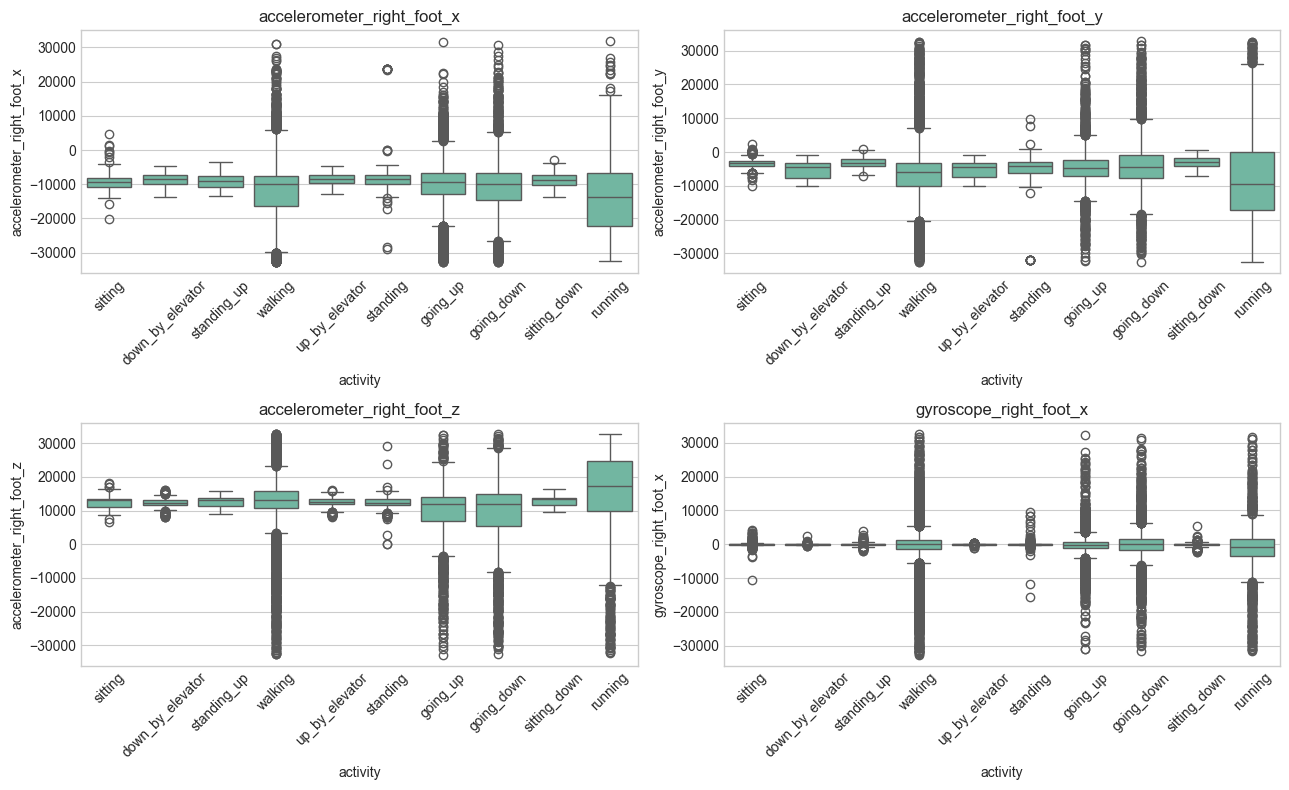

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.flat, IMU_COLS[:4]):
    sns.boxplot(x='activity', y=col, data=df.sample(min(20000, len(df)), random_state=RANDOM_STATE), ax=ax)
    ax.set_title(col)
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

## Корреляция между сенсорами (сырые сигналы)

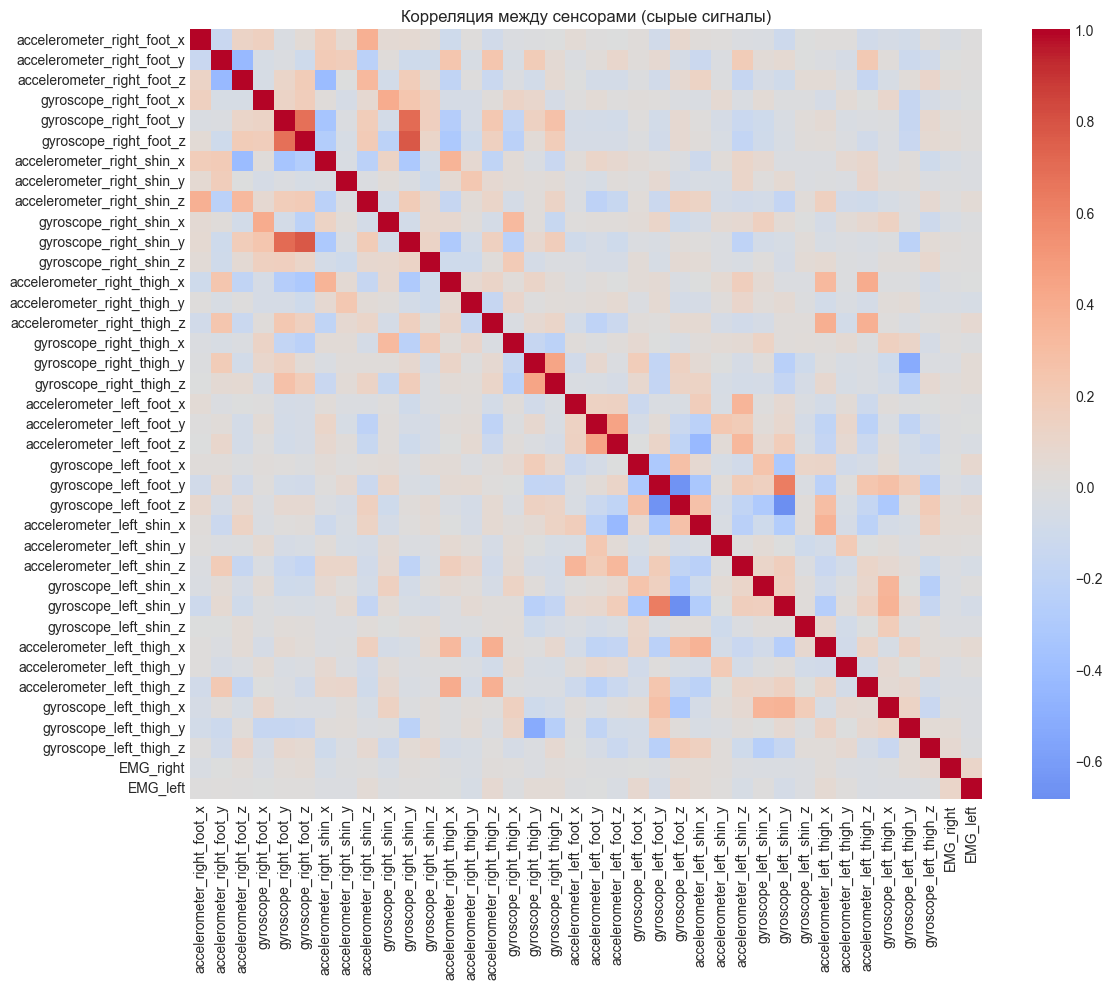

In [16]:
plt.figure(figsize=(12, 10))
sns.heatmap(df[SENSOR_COLS].sample(min(50000, len(df)), random_state=RANDOM_STATE).corr(),
            cmap='coolwarm', center=0)
plt.title('Корреляция между сенсорами (сырые сигналы)')
plt.tight_layout()
plt.show()

## Частотный анализ FFT

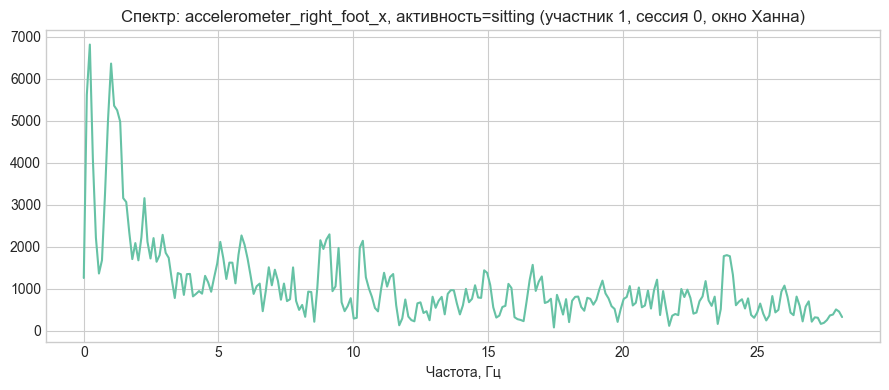

In [17]:
activity_in_example = example['activity'].mode()[0]
segment_mask = example['activity'] == activity_in_example
walking_signal = example.loc[segment_mask, example_col].to_numpy()
walking_signal = walking_signal[:min(500, len(walking_signal))]

n = len(walking_signal)
hann_window = np.hanning(n) if n > 1 else np.ones(n)
centered = walking_signal - walking_signal.mean()
yf = np.abs(rfft(centered * hann_window))
xf = rfftfreq(n, d=1 / SAMPLING_RATE_HZ)

plt.figure(figsize=(9, 4))
plt.plot(xf, yf)
plt.title(f'Спектр: {example_col}, активность={activity_in_example} '
          f'(участник {subj}, сессия {sess}, окно Ханна)')
plt.xlabel('Частота, Гц')
plt.tight_layout()
plt.show()

## PCA на сырых сигналах

C:\Users\user\AppData\Local\Temp\ipykernel_15104\1956282983.py:9: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()


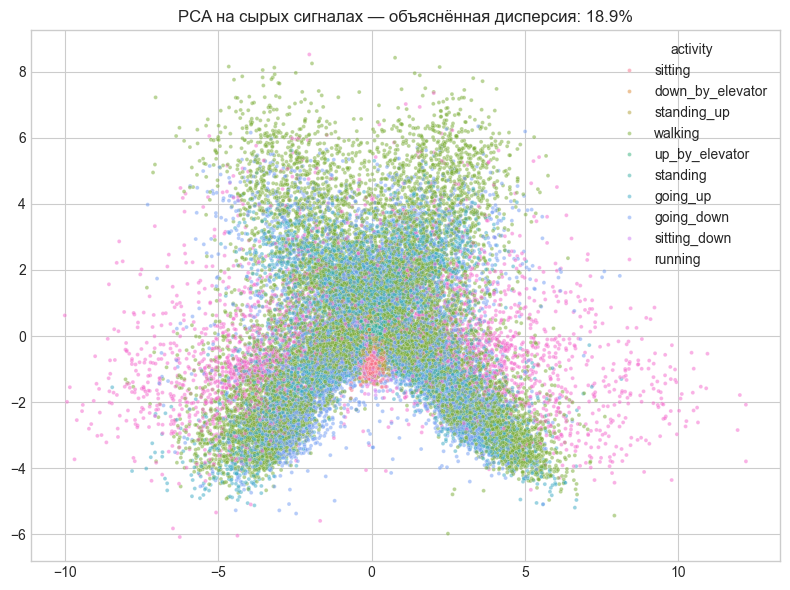

In [18]:
sample = df.sample(min(50000, len(df)), random_state=RANDOM_STATE)
X_raw_scaled = StandardScaler().fit_transform(sample[SENSOR_COLS])
pca_raw = PCA(n_components=2, random_state=RANDOM_STATE)
X_raw_pca = pca_raw.fit_transform(X_raw_scaled)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_raw_pca[:, 0], y=X_raw_pca[:, 1], hue=sample['activity'], s=8, alpha=0.5)
plt.title(f'PCA на сырых сигналах — объяснённая дисперсия: {pca_raw.explained_variance_ratio_.sum():.1%}')
plt.tight_layout()
plt.show()

## Windowing и Feature Engineering 

In [19]:
def zero_crossing_rate(x):
    """np.signbit трактует 0.0 как неотрицательное — в отличие от np.sign (которое даёт
    для x==0 отдельное значение), не создаёт лишний 'фантомный' переход в точке среднего."""
    x = x - x.mean()
    return np.sum(np.signbit(x[:-1]) != np.signbit(x[1:])) / len(x)

HANN_WINDOW = np.hanning(WINDOW_SIZE)

def axis_triplets(cols):
    """Группирует колонки вида '<sensor>_<axis>' (x/y/z) в тройки — строится
    автоматически из имён колонок, ничего не хардкодится."""
    triplets = {}
    for col in cols:
        m = re.match(r'(.+)_(x|y|z)$', col, flags=re.IGNORECASE)
        if m:
            triplets.setdefault(m.group(1), []).append(col)
    return {base: sorted(axes) for base, axes in triplets.items() if len(axes) == 3}

IMU_AXIS_TRIPLETS = axis_triplets(IMU_COLS)
print(f"Найдено {len(IMU_AXIS_TRIPLETS)} троек осей: {list(IMU_AXIS_TRIPLETS.keys())}")
if not IMU_AXIS_TRIPLETS:
    print("⚠ Не нашлось ни одной тройки x/y/z по именам колонок — magnitude/SMA не будут посчитаны.")

def extract_window_features(window, imu_cols, emg_cols, triplets):
    feats = {}
    for col in imu_cols:
        s = window[col].to_numpy()
        feats[f'{col}_mean'] = s.mean()
        feats[f'{col}_std'] = s.std()
        feats[f'{col}_min'] = s.min()
        feats[f'{col}_max'] = s.max()
        feats[f'{col}_median'] = np.median(s)
        feats[f'{col}_zcr'] = zero_crossing_rate(s)
        n = len(s)
        win = HANN_WINDOW[:n] if n == WINDOW_SIZE else np.hanning(n)
        yf = np.abs(rfft((s - s.mean()) * win))
        xf = rfftfreq(n, d=1 / SAMPLING_RATE_HZ)
        feats[f'{col}_dom_freq'] = xf[np.argmax(yf)] if len(yf) else 0.0
        feats[f'{col}_energy'] = np.sum(yf ** 2) / n
    for sensor, axes in triplets.items():
        vecs = np.stack([window[c].to_numpy() for c in axes], axis=1)
        magnitude = np.sqrt((vecs ** 2).sum(axis=1))
        feats[f'{sensor}_mag_mean'] = magnitude.mean()
        feats[f'{sensor}_mag_std'] = magnitude.std()
        feats[f'{sensor}_sma'] = np.abs(vecs).sum(axis=1).mean()
    for col in emg_cols:
        s = window[col].to_numpy().astype(np.float64)
        feats[f'{col}_mav'] = np.abs(s - s.mean()).mean()
        feats[f'{col}_rms'] = np.sqrt((s ** 2).mean())
    return feats

rows = []
skipped_impure = 0
for (subj_g, sess_g), g in df.groupby(['subject_id', 'session_id']):
    g = g.reset_index(drop=True)
    for start in range(0, len(g) - WINDOW_SIZE + 1, STEP_SIZE):
        window = g.iloc[start:start + WINDOW_SIZE]
        vc = window['activity'].value_counts(normalize=True)
        if vc.iloc[0] < PURITY_THRESHOLD:
            skipped_impure += 1
            continue
        f = extract_window_features(window, IMU_COLS, EMG_COLS, IMU_AXIS_TRIPLETS)
        f['activity'] = vc.index[0]
        f['subject_id'] = subj_g
        f['session_id'] = sess_g
        rows.append(f)

features_df = pd.DataFrame(rows)
print(f"\nОкон построено: {len(features_df)}, отброшено как смешанные: {skipped_impure}")
print(f"Размер таблицы признаков: {features_df.shape}")

feature_cols_preview = [c for c in features_df.columns if c not in METADATA_COLS]
assert features_df[feature_cols_preview].isna().sum().sum() == 0, \
    "NaN в признаках — модель обучится на них без ошибки"

Найдено 12 троек осей: ['accelerometer_right_foot', 'gyroscope_right_foot', 'accelerometer_right_shin', 'gyroscope_right_shin', 'accelerometer_right_thigh', 'gyroscope_right_thigh', 'accelerometer_left_foot', 'gyroscope_left_foot', 'accelerometer_left_shin', 'gyroscope_left_shin', 'accelerometer_left_thigh', 'gyroscope_left_thigh']

Окон построено: 18113, отброшено как смешанные: 4082
Размер таблицы признаков: (18113, 331)


## Баланс классов на уровне окон

                  windows  percent
activity                          
walking              5139    28.37
standing             3450    19.05
going_up             2195    12.12
going_down           1859    10.26
up_by_elevator       1658     9.15
down_by_elevator     1257     6.94
sitting              1239     6.84
running              1234     6.81
standing_up            52     0.29
sitting_down           30     0.17


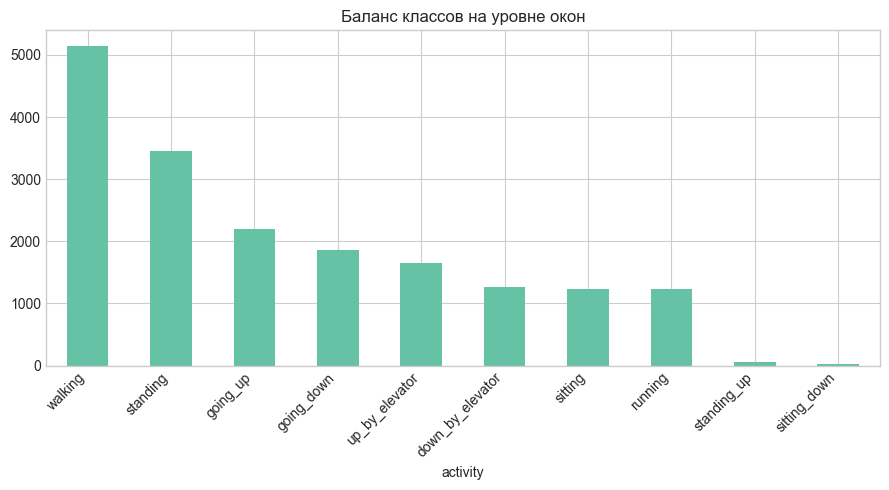

In [20]:
window_counts = features_df['activity'].value_counts()
print(pd.DataFrame({'windows': window_counts,
                     'percent': (window_counts / len(features_df) * 100).round(2)}))

fig, ax = plt.subplots(figsize=(9, 5))
window_counts.plot(kind='bar', ax=ax)
ax.set_title('Баланс классов на уровне окон')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## train/test 

In [21]:
all_feature_cols = [c for c in features_df.columns if c not in METADATA_COLS]
X_full = features_df[all_feature_cols].copy()
y = features_df['activity'].copy()
groups = features_df['subject_id'].copy()

assert 'subject_id' not in X_full.columns and 'session_id' not in X_full.columns

splitter = GroupShuffleSplit(test_size=0.3, n_splits=1, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X_full, y, groups=groups))

X_train_full, X_test_full = X_full.iloc[train_idx], X_full.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train, groups_test = groups.iloc[train_idx], groups.iloc[test_idx]

overlap = set(groups_train) & set(groups_test)
print(f"Train субъектов: {sorted(groups_train.unique())}")
print(f"Test субъектов:  {sorted(groups_test.unique())}")
assert len(overlap) == 0, "УТЕЧКА: субъект оказался и в train, и в test!"

Train субъектов: [np.int64(3), np.int64(5), np.int64(7), np.int64(8), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(15), np.int64(16), np.int64(17), np.int64(18)]
Test субъектов:  [np.int64(1), np.int64(2), np.int64(4), np.int64(6), np.int64(9), np.int64(14)]


## Отбор признаков по корреляции 

In [22]:
corr = X_train_full.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
to_drop = [c for c in upper.columns if (upper[c] > CORR_THRESHOLD).any()]

print(f"Удаляется {len(to_drop)} скоррелированных признаков (посчитано только на train) "
      f"из {len(all_feature_cols)}")
feature_cols = [c for c in all_feature_cols if c not in to_drop]
print(f"Осталось признаков: {len(feature_cols)}")

X_train = X_train_full[feature_cols]
X_test = X_test_full[feature_cols]

Удаляется 99 скоррелированных признаков (посчитано только на train) из 328
Осталось признаков: 229


## Baseline

In [23]:
for strat in ['most_frequent', 'stratified']:
    dummy = DummyClassifier(strategy=strat, random_state=RANDOM_STATE)
    dummy.fit(X_train, y_train)
    print(f"DummyClassifier('{strat}'): accuracy = {dummy.score(X_test, y_test):.3f}")

DummyClassifier('most_frequent'): accuracy = 0.364
DummyClassifier('stratified'): accuracy = 0.169


## LOSO (Leave-One-Subject-Out)

In [24]:
X_selected = X_full[feature_cols]
logo = LeaveOneGroupOut()
n_loso = logo.get_n_splits(groups=groups)
print(f"LOSO: {n_loso} фолдов (по одному участнику)")

rf_for_loso = RandomForestClassifier(n_estimators=200, class_weight='balanced',
                                      random_state=RANDOM_STATE, n_jobs=-1)
loso_scores = cross_val_score(rf_for_loso, X_selected, y, groups=groups, cv=logo, scoring='f1_macro')

print(f"\nLOSO macro-F1 по участникам: {loso_scores.round(3)}")
print(f"Среднее: {loso_scores.mean():.3f} +/- {loso_scores.std():.3f} "
      f"(min={loso_scores.min():.3f}, max={loso_scores.max():.3f})")
print("\nБольшой разброс между участниками — нормально:"
      "модель не одинаково хорошо генерализуется на КАЖДОГО нового человека.")

LOSO: 18 фолдов (по одному участнику)

LOSO macro-F1 по участникам: [0.998 0.956 0.903 0.815 0.86  0.81  0.792 0.815 0.873 0.884 0.904 0.9
 0.88  0.871 1.    0.82  0.827 0.998]
Среднее: 0.884 +/- 0.065 (min=0.792, max=1.000)

Большой разброс между участниками — нормально:модель не одинаково хорошо генерализуется на КАЖДОГО нового человека.


## StandardScaler и веса классов

In [25]:
sample_weight_train = compute_sample_weight('balanced', y_train)

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=feature_cols, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=feature_cols, index=X_test.index) 

_rf_check_raw = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
_rf_check_raw.fit(X_train, y_train, sample_weight=sample_weight_train)
_rf_check_scaled = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
_rf_check_scaled.fit(X_train_scaled, y_train, sample_weight=sample_weight_train)

_agreement = (_rf_check_raw.predict(X_test) == _rf_check_scaled.predict(X_test_scaled)).mean()
print(f"Совпадение предсказаний RandomForest со scaler и без: {_agreement:.4f}")

assert _agreement > 0.95, ("Совпадение предсказаний со scaler/без ниже 95% - это уже больше, чем "
                            "обычный пограничный эффект выбора сплита, стоит проверить NaN/inf в данных")
print("Как и ожидалось для модели на деревьях"
      "X_train/X_test (для консистентности с уже посчитанными LOSO/permutation importance), "
      "а X_train_scaled/X_test_scaled остаются доступны, если решите добавить не-древесную модель.")

Совпадение предсказаний RandomForest со scaler и без: 0.9843
Как и ожидалось для модели на деревьяхX_train/X_test (для консистентности с уже посчитанными LOSO/permutation importance), а X_train_scaled/X_test_scaled остаются доступны, если решите добавить не-древесную модель.


## Модели

In [26]:
model_results = []
predictions = {}

def _evaluate(name, pred):
    predictions[name] = pred
    model_results.append({
        'model': name,
        'accuracy': (pred == y_test).mean(),
        'balanced_accuracy': balanced_accuracy_score(y_test, pred),
        'macro_f1': f1_score(y_test, pred, average='macro', zero_division=0),
    })

dt = DecisionTreeClassifier(max_depth=15, class_weight='balanced', random_state=RANDOM_STATE)
dt.fit(X_train, y_train)
_evaluate('DecisionTree', dt.predict(X_test))

rf = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(X_train, y_train, sample_weight=sample_weight_train)
_evaluate('RandomForest', rf.predict(X_test))

hgb = HistGradientBoostingClassifier(random_state=RANDOM_STATE)
hgb.fit(X_train, y_train, sample_weight=sample_weight_train)
_evaluate('HistGradientBoosting', hgb.predict(X_test))

xgb_model = None
try:
    from xgboost import XGBClassifier
    xgb_label_encoder = LabelEncoder()
    y_train_enc = xgb_label_encoder.fit_transform(y_train)
    xgb_model = XGBClassifier(n_estimators=300, max_depth=8, random_state=RANDOM_STATE,
                               eval_metric='mlogloss', n_jobs=-1)
    xgb_model.fit(X_train, y_train_enc, sample_weight=sample_weight_train)
    _evaluate('XGBoost', xgb_label_encoder.inverse_transform(xgb_model.predict(X_test)))
except ImportError:
    print("XGBoost не установлена (pip install xgboost --break-system-packages) - пропускаем.")

cb_model = None
try:
    from catboost import CatBoostClassifier
    cb_model = CatBoostClassifier(iterations=300, depth=8, random_seed=RANDOM_STATE, verbose=False)
    cb_model.fit(X_train, y_train, sample_weight=sample_weight_train)
    _evaluate('CatBoost', cb_model.predict(X_test).ravel())  
except ImportError:
    print("CatBoost не установлена (pip install catboost --break-system-packages) - пропускаем.")

model_comparison_df = pd.DataFrame(model_results).sort_values('macro_f1', ascending=False)
print(model_comparison_df.to_string(index=False))

pred_rf = predictions['RandomForest']
pred_hgb = predictions['HistGradientBoosting']

for _name in ['RandomForest', 'HistGradientBoosting']:
    _pred = predictions[_name]
    print(f"\n--- {_name} (held-out split, sample_weight='balanced') ---")
    print(f"accuracy={(_pred==y_test).mean():.3f}  "
          f"balanced_accuracy={balanced_accuracy_score(y_test,_pred):.3f}  "
          f"macro_f1={f1_score(y_test,_pred,average='macro',zero_division=0):.3f}")
    print(classification_report(y_test, _pred, zero_division=0))

               model  accuracy  balanced_accuracy  macro_f1
        RandomForest  0.887283           0.854801  0.858114
             XGBoost  0.886962           0.854158  0.857297
HistGradientBoosting  0.885196           0.852183  0.856972
            CatBoost  0.878773           0.841866  0.846347
        DecisionTree  0.836384           0.780996  0.791087

--- RandomForest (held-out split, sample_weight='balanced') ---
accuracy=0.887  balanced_accuracy=0.855  macro_f1=0.858
                  precision    recall  f1-score   support

down_by_elevator       0.61      0.24      0.34       414
      going_down       1.00      0.98      0.99       490
        going_up       0.96      0.99      0.98       580
         running       0.99      1.00      1.00       588
         sitting       1.00      1.00      1.00       295
    sitting_down       1.00      1.00      1.00        15
        standing       0.68      0.96      0.79      1022
     standing_up       1.00      0.96      0.98       

## Train/validation loss

Внутренний train: 9298 окон, 9 субъектов | val: 2587 окон, 3 субъектов


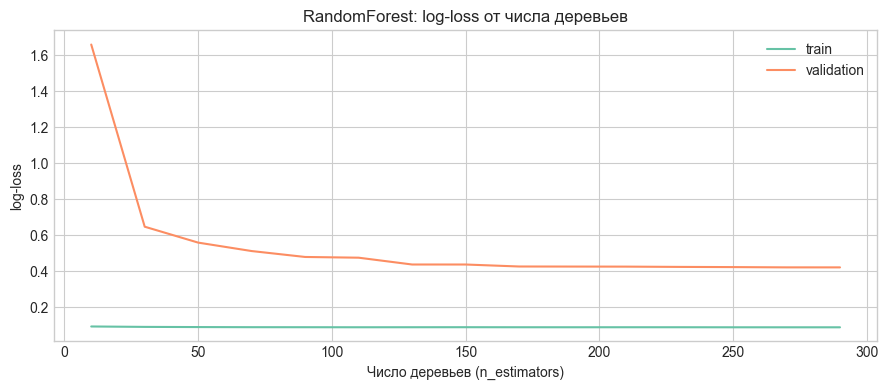

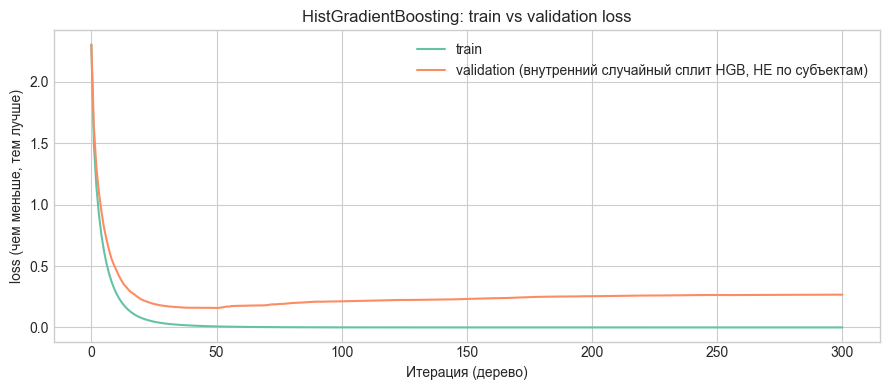

HistGradientBoostingClassifier не принимает внешний eval_set - validation_fraction внутри него откалывает случайные СТРОКИ, а не субъектов. Эта кривая - диагностика сходимости/переобучения В ПРЕДЕЛАХ train, а не оценка обобщения на новый субъект (для этого есть LOSO и test).
Разрыв train/val loss на последней итерации: -0.2666 (расходящиеся кривые = переобучение при данном числе итераций)


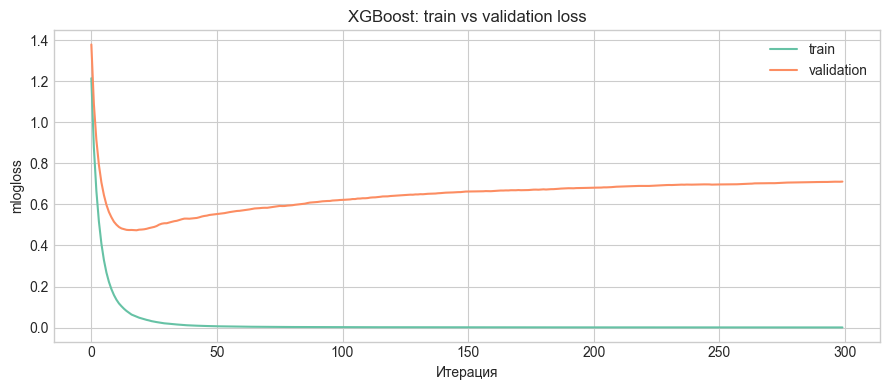

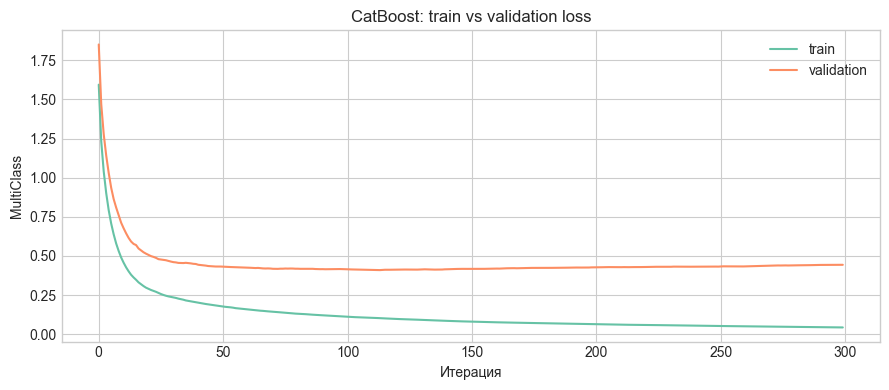

In [ ]:
val_splitter = GroupShuffleSplit(test_size=0.2, n_splits=1, random_state=RANDOM_STATE)
tr_idx, val_idx = next(val_splitter.split(X_train, y_train, groups=groups_train))
X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]
groups_tr_inner, groups_val_inner = groups_train.iloc[tr_idx], groups_train.iloc[val_idx]
assert len(set(groups_tr_inner) & set(groups_val_inner)) == 0, "УТЕЧКА между train/val!"
sample_weight_tr = compute_sample_weight('balanced', y_tr)
print(f"Внутренний train: {len(X_tr)} окон, {groups_tr_inner.nunique()} субъектов | "
      f"val: {len(X_val)} окон, {groups_val_inner.nunique()} субъектов")

n_estimators_steps = list(range(10, 301, 20))
rf_curve = RandomForestClassifier(warm_start=True, random_state=RANDOM_STATE, n_jobs=-1)
train_losses, val_losses = [], []

val_classes_missing_from_train = set(y_val.unique()) - set(y_tr.unique())
if val_classes_missing_from_train:
    print(f"⚠ Классы {val_classes_missing_from_train} есть в val, но отсутствуют во внутреннем "
          f"train (мало примеров + group-based split) - log-loss для них не определён, "
          f"эти строки val будут исключены из кривой ниже.")

for n in n_estimators_steps:
    rf_curve.n_estimators = n
    rf_curve.fit(X_tr, y_tr, sample_weight=sample_weight_tr)
    train_losses.append(log_loss(y_tr, rf_curve.predict_proba(X_tr), labels=rf_curve.classes_))
    val_mask_known = y_val.isin(rf_curve.classes_)
    val_losses.append(log_loss(y_val[val_mask_known], rf_curve.predict_proba(X_val[val_mask_known]),
                                labels=rf_curve.classes_))

plt.figure(figsize=(9, 4))
plt.plot(n_estimators_steps, train_losses, label='train')
plt.plot(n_estimators_steps, val_losses, label='validation')
plt.xlabel('Число деревьев (n_estimators)'); plt.ylabel('log-loss')
plt.title('RandomForest: log-loss от числа деревьев')
plt.legend(); plt.tight_layout(); plt.show()

hgb_curve = HistGradientBoostingClassifier(
    random_state=RANDOM_STATE, early_stopping=True, validation_fraction=0.15,
    scoring='loss', max_iter=300, n_iter_no_change=300,
)
hgb_curve.fit(X_tr, y_tr, sample_weight=sample_weight_tr)

plt.figure(figsize=(9, 4))
plt.plot(-hgb_curve.train_score_, label='train')  
plt.plot(-hgb_curve.validation_score_, label='validation (внутренний случайный сплит HGB, НЕ по субъектам)')
plt.xlabel('Итерация (дерево)'); plt.ylabel('loss (чем меньше, тем лучше)')
plt.title('HistGradientBoosting: train vs validation loss')
plt.legend(); plt.tight_layout(); plt.show()

print("HistGradientBoostingClassifier не принимает внешний eval_set - "
      "validation_fraction внутри него откалывает случайные СТРОКИ, а не субъектов. "
      "Эта кривая - диагностика сходимости/переобучения В ПРЕДЕЛАХ train ")

gap = (-hgb_curve.train_score_[-1]) - (-hgb_curve.validation_score_[-1])
print(f"Разрыв train/val loss на последней итерации: {gap:.4f} "
      f"(расходящиеся кривые = переобучение при данном числе итераций)")

if xgb_model is not None:
    y_tr_enc = xgb_label_encoder.transform(y_tr)
    y_val_enc = xgb_label_encoder.transform(y_val)
    xgb_curve = XGBClassifier(n_estimators=300, max_depth=8, random_state=RANDOM_STATE,
                               eval_metric='mlogloss', n_jobs=-1)
    xgb_curve.fit(X_tr, y_tr_enc, sample_weight=sample_weight_tr,
                  eval_set=[(X_tr, y_tr_enc), (X_val, y_val_enc)], verbose=False)
    _ev = xgb_curve.evals_result()
    plt.figure(figsize=(9, 4))
    plt.plot(_ev['validation_0']['mlogloss'], label='train')
    plt.plot(_ev['validation_1']['mlogloss'], label='validation')
    plt.xlabel('Итерация'); plt.ylabel('mlogloss'); plt.legend()
    plt.title('XGBoost: train vs validation loss'); plt.tight_layout(); plt.show()

if cb_model is not None:
    cb_curve = CatBoostClassifier(iterations=300, depth=8, random_seed=RANDOM_STATE, verbose=False)
    cb_curve.fit(X_tr, y_tr, sample_weight=sample_weight_tr, eval_set=(X_val, y_val))
    _ev = cb_curve.get_evals_result()
    _metric_name = list(_ev['learn'].keys())[0]  
    plt.figure(figsize=(9, 4))
    plt.plot(_ev['learn'][_metric_name], label='train')
    plt.plot(_ev['validation'][_metric_name], label='validation')
    plt.xlabel('Итерация'); plt.ylabel(_metric_name); plt.legend()
    plt.title('CatBoost: train vs validation loss'); plt.tight_layout(); plt.show()

## Важность признаков: MDI + permutation importance

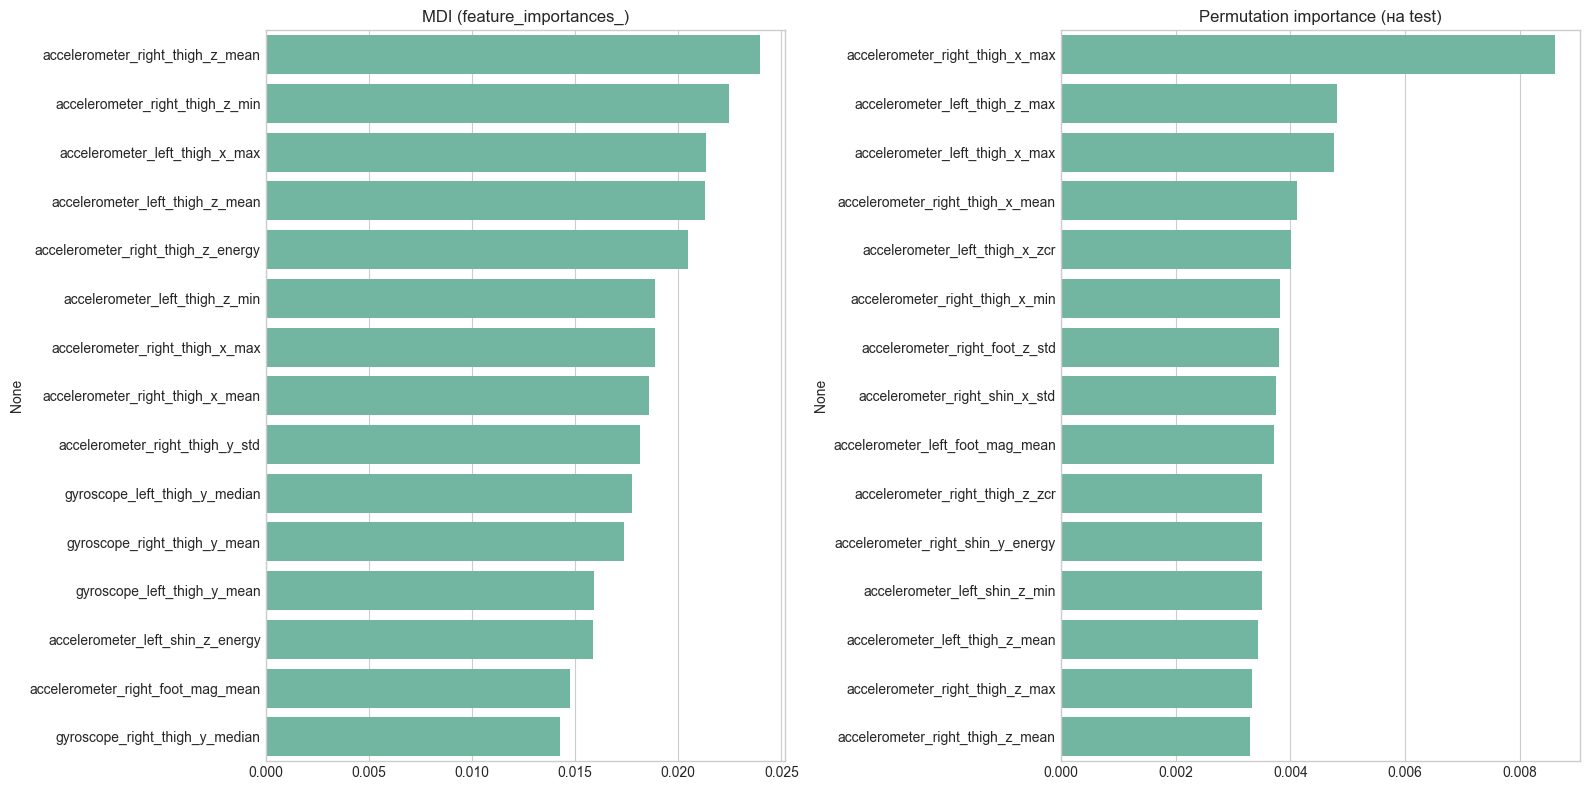

In [28]:
mdi_importances = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=False)
perm = permutation_importance(rf, X_test, y_test, n_repeats=10, random_state=RANDOM_STATE, scoring='f1_macro')
perm_importances = pd.Series(perm.importances_mean, index=feature_cols).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
sns.barplot(x=mdi_importances.head(15).values, y=mdi_importances.head(15).index, ax=axes[0])
axes[0].set_title('MDI (feature_importances_)')
sns.barplot(x=perm_importances.head(15).values, y=perm_importances.head(15).index, ax=axes[1])
axes[1].set_title('Permutation importance (на test)')
plt.tight_layout()
plt.show()

assert not any('subject' in f or 'session' in f for f in mdi_importances.head(15).index), \
    "metadata просочилась обратно в признаки — проверьте feature_cols"

## Confusion matrix

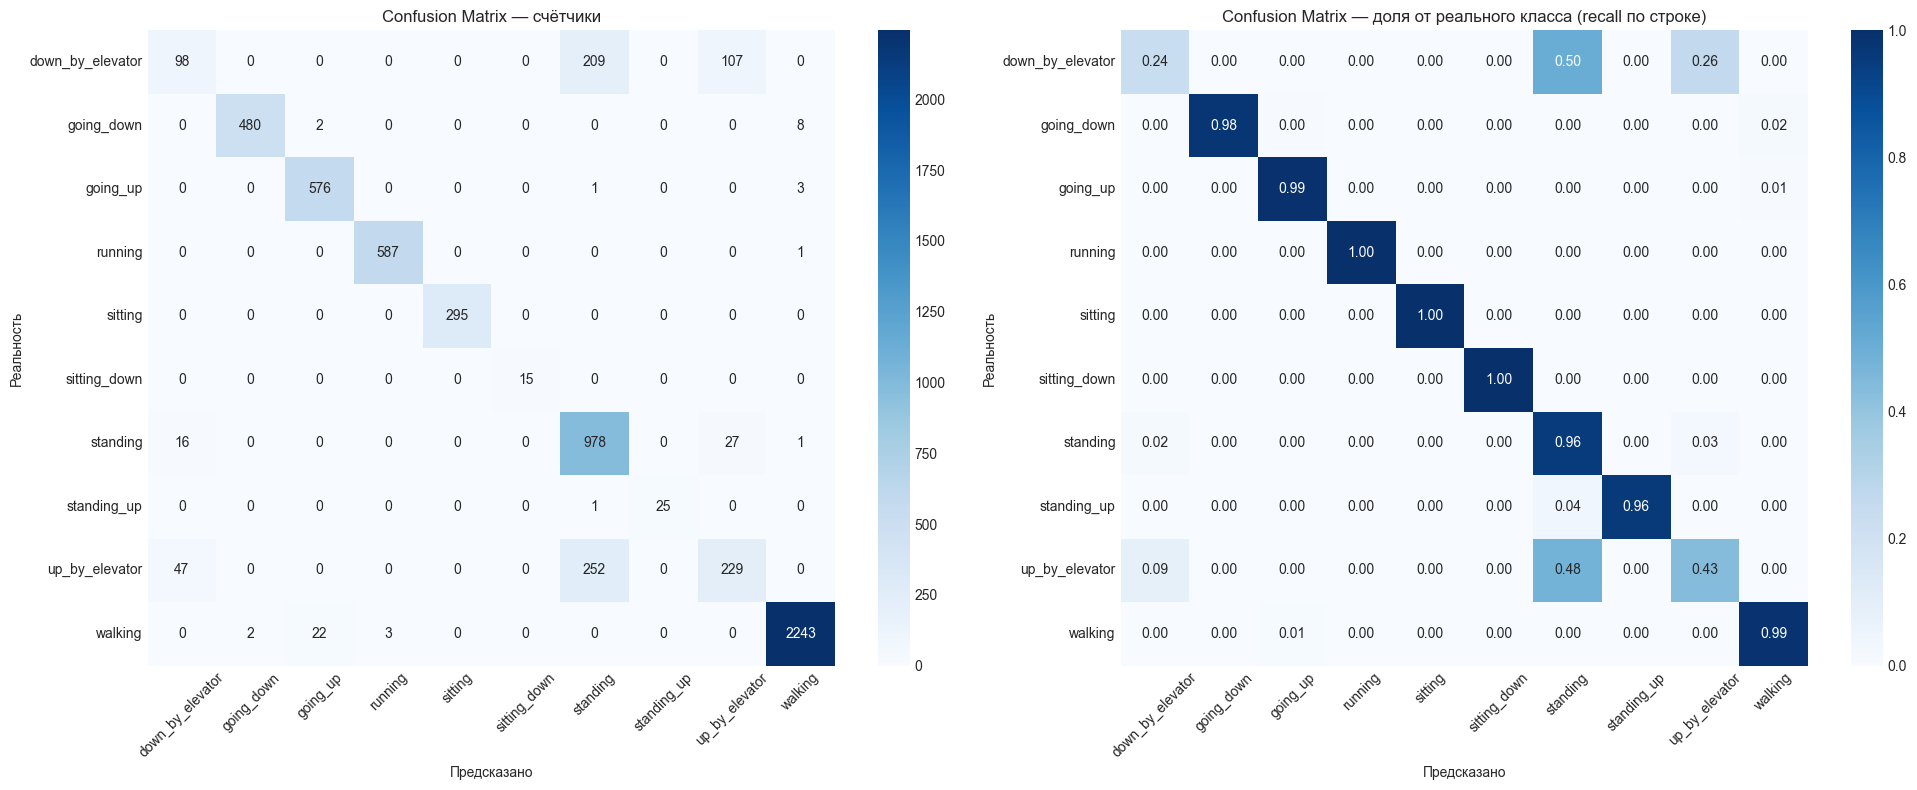

Топ-10 самых частых ошибок (реальность -> предсказано):
      реальность      предсказано  count  percent_of_true_class
  up_by_elevator         standing    252               0.477273
down_by_elevator         standing    209               0.504831
down_by_elevator   up_by_elevator    107               0.258454
  up_by_elevator down_by_elevator     47               0.089015
        standing   up_by_elevator     27               0.026419
         walking         going_up     22               0.009692
        standing down_by_elevator     16               0.015656
      going_down          walking      8               0.016327
         walking          running      3               0.001322
        going_up          walking      3               0.005172


In [29]:
labels_sorted = sorted(y.unique())
cm = confusion_matrix(y_test, pred_rf, labels=labels_sorted)
cm_normalized = confusion_matrix(y_test, pred_rf, labels=labels_sorted, normalize='true')

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels_sorted, yticklabels=labels_sorted, ax=axes[0])
axes[0].set_xlabel('Предсказано'); axes[0].set_ylabel('Реальность')
axes[0].set_title('Confusion Matrix — счётчики')
axes[0].tick_params(axis='x', rotation=45)

sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues', xticklabels=labels_sorted, yticklabels=labels_sorted, ax=axes[1])
axes[1].set_xlabel('Предсказано'); axes[1].set_ylabel('Реальность')
axes[1].set_title('Confusion Matrix — доля от реального класса (recall по строке)')
axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

cm_df = pd.DataFrame(cm, index=labels_sorted, columns=labels_sorted)
confusions = []
for true_label in labels_sorted:
    for pred_label in labels_sorted:
        if true_label != pred_label and cm_df.loc[true_label, pred_label] > 0:
            confusions.append({
                'реальность': true_label, 'предсказано': pred_label,
                'count': int(cm_df.loc[true_label, pred_label]),
                'percent_of_true_class': cm_df.loc[true_label, pred_label] / cm_df.loc[true_label].sum(),
            })
top10_confused = pd.DataFrame(confusions).sort_values('count', ascending=False).head(10)
print("Топ-10 самых частых ошибок (реальность -> предсказано):")
print(top10_confused.to_string(index=False))

Субъектов в train: 12, в test: 6, пересечение: 0

Held-out macro-F1: 0.858
LOSO mean +/- std: 0.884 +/- 0.065
Отклонение held-out от LOSO-среднего: -0.39 std
Если бы held-out-сплит протекал, он оказался бы заметно ВЫШЕ этого распределения, а не примерно внутри него.


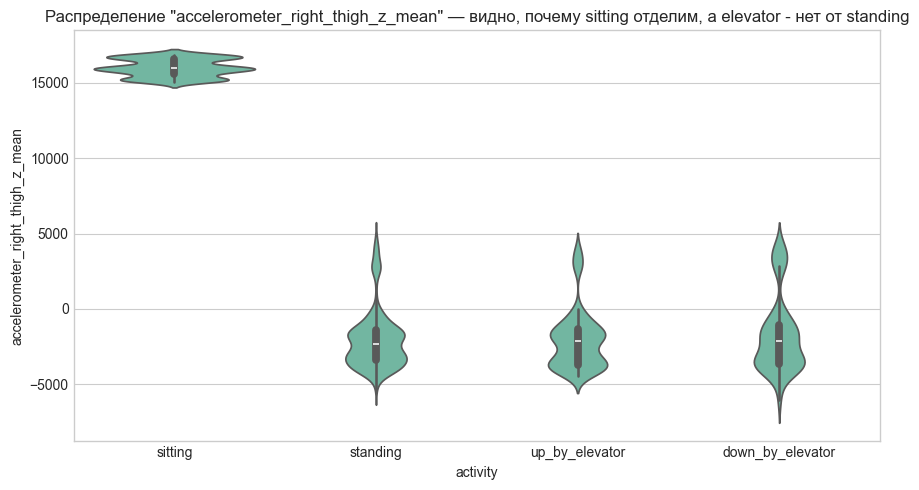

In [30]:
train_subjects_final = set(groups_train.unique())
test_subjects_final = set(groups_test.unique())
assert len(train_subjects_final & test_subjects_final) == 0, "УТЕЧКА: субъект в train и test одновременно"
print(f"Субъектов в train: {len(train_subjects_final)}, в test: {len(test_subjects_final)}, "
      f"пересечение: {len(train_subjects_final & test_subjects_final)}")

rf_macro_f1_heldout = f1_score(y_test, pred_rf, average='macro', zero_division=0)
z_like = (rf_macro_f1_heldout - loso_scores.mean()) / loso_scores.std()
print(f"\nHeld-out macro-F1: {rf_macro_f1_heldout:.3f}")
print(f"LOSO mean +/- std: {loso_scores.mean():.3f} +/- {loso_scores.std():.3f}")
print(f"Отклонение held-out от LOSO-среднего: {z_like:+.2f} std")
print("Если бы held-out-сплит протекал, он оказался бы заметно ВЫШЕ этого распределения, "
      "а не примерно внутри него.")

thigh_z_candidates = [c for c in feature_cols if 'thigh' in c and c.endswith('_z_mean')]
if thigh_z_candidates:
    col = thigh_z_candidates[0]
    check_classes = [c for c in ['sitting', 'standing', 'up_by_elevator', 'down_by_elevator']
                      if c in y_test.unique()]
    plot_df = X_test.loc[y_test.isin(check_classes), [col]].copy()
    plot_df['activity'] = y_test[y_test.isin(check_classes)].values
    plt.figure(figsize=(9, 5))
    sns.violinplot(x='activity', y=col, data=plot_df)
    plt.title(f'Распределение "{col}" — видно, почему sitting отделим, а elevator - нет от standing')
    plt.tight_layout()
    plt.show()
else:
    print("Колонка thigh z-mean не нашлась в feature_cols (могла быть выброшена на этапе "
          "корреляционного отбора, раздел 18) - визуальную проверку (3) пропускаем, "
          "но выводы (1) и (2) от неё не зависят.")

## ROC, Precision-Recall, Calibration curves

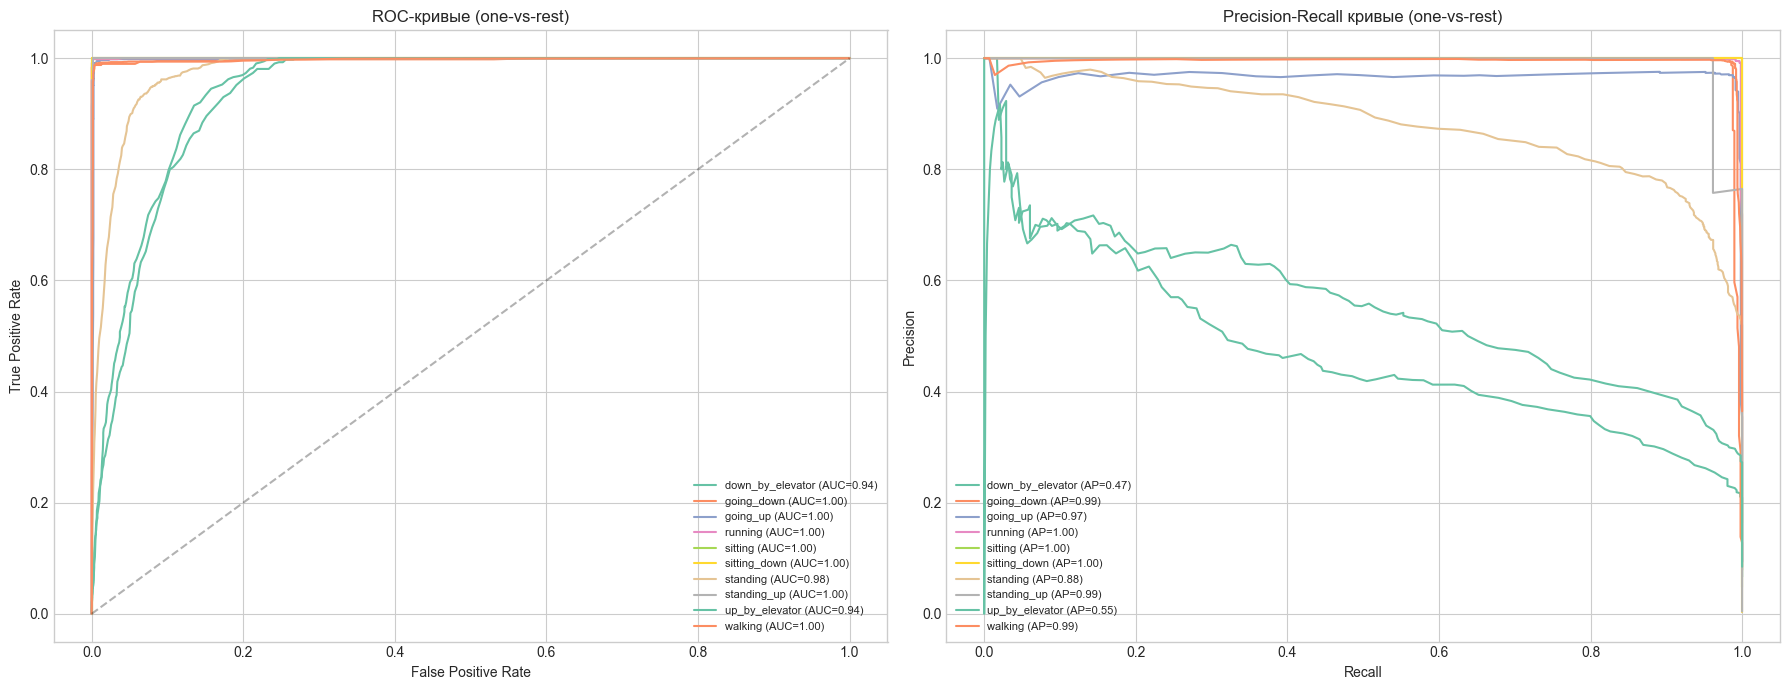

Сравните AUC и AP именно для down_by_elevator/up_by_elevator - разрыв между ними и есть иллюстрация того, что ROC переоценивает эти классы относительно PR.


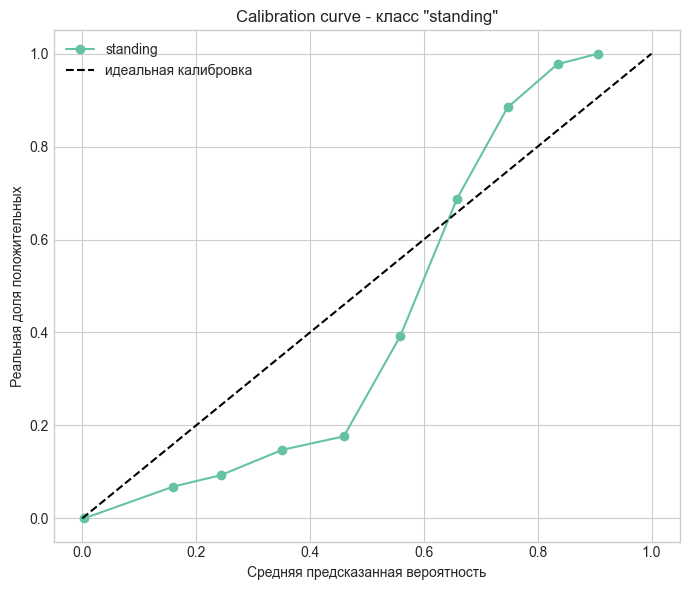

Калибровка важна, если решения принимаются по ВЕРОЯТНОСТИ (например, порог отсечения ниже 0.5), а не только по argmax, как везде выше в этом ноутбуке - тогда это скорее диагностика на будущее, чем обязательный компонент текущей оценки.


In [ ]:
classes_sorted = list(rf.classes_)
y_test_bin = label_binarize(y_test, classes=classes_sorted)
y_proba_rf = rf.predict_proba(X_test)

classes_with_support = [cls for cls in classes_sorted if (y_test == cls).sum() > 0]
classes_without_support = set(classes_sorted) - set(classes_with_support)
if classes_without_support:
    print(f"⚠ В этом test-сплите нет примеров классов {classes_without_support} - "
          f"для них ROC/PR не определены, пропускаем именно эти кривые.")

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for cls in classes_with_support:
    i = classes_sorted.index(cls)
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_proba_rf[:, i])
    roc_auc = auc(fpr, tpr)
    axes[0].plot(fpr, tpr, label=f'{cls} (AUC={roc_auc:.2f})')
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.3)
axes[0].set_xlabel('False Positive Rate'); axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC-кривые (one-vs-rest)')
axes[0].legend(fontsize=8, loc='lower right')

for cls in classes_with_support:
    i = classes_sorted.index(cls)
    precision, recall, _ = precision_recall_curve(y_test_bin[:, i], y_proba_rf[:, i])
    ap = average_precision_score(y_test_bin[:, i], y_proba_rf[:, i])
    axes[1].plot(recall, precision, label=f'{cls} (AP={ap:.2f})')
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall кривые (one-vs-rest)')
axes[1].legend(fontsize=8, loc='lower left')
plt.tight_layout()
plt.show()

print("Сравните AUC и AP именно для down_by_elevator/up_by_elevator - разрыв между ними "
      "и есть иллюстрация того, что ROC переоценивает эти классы относительно PR.")

target_class_for_calibration = 'standing' if 'standing' in classes_with_support else classes_with_support[0]
idx_cls = classes_sorted.index(target_class_for_calibration)
prob_true, prob_pred = calibration_curve(y_test_bin[:, idx_cls], y_proba_rf[:, idx_cls], n_bins=10)

plt.figure(figsize=(7, 6))
plt.plot(prob_pred, prob_true, marker='o', label=target_class_for_calibration)
plt.plot([0, 1], [0, 1], 'k--', label='идеальная калибровка')
plt.xlabel('Средняя предсказанная вероятность'); plt.ylabel('Реальная доля положительных')
plt.title(f'Calibration curve - класс "{target_class_for_calibration}"')
plt.legend(); plt.tight_layout(); plt.show()

print("Калибровка важна, если решения принимаются по ВЕРОЯТНОСТИ (например, порог "
      "отсечения ниже 0.5), а не только по argmax")

In [32]:
SPLIT_CONFIGS = {
    '70/15/15': (0.70, 0.15, 0.15),
    '80/10/10': (0.80, 0.10, 0.10),
}
N_SEEDS = 5
split_comparison_rows = []

for config_name, (train_pct, val_pct, test_pct) in SPLIT_CONFIGS.items():
    for seed in range(N_SEEDS):
        s1 = GroupShuffleSplit(test_size=test_pct, n_splits=1, random_state=seed)
        trainval_idx, test_idx_cfg = next(s1.split(X_full, y, groups=groups))

        val_share_within_trainval = val_pct / (train_pct + val_pct)
        s2 = GroupShuffleSplit(test_size=val_share_within_trainval, n_splits=1, random_state=seed)
        gv_trainval = groups.iloc[trainval_idx]
        tr_rel, val_rel = next(s2.split(X_full.iloc[trainval_idx], y.iloc[trainval_idx], groups=gv_trainval))
        tr_idx_cfg, val_idx_cfg = trainval_idx[tr_rel], trainval_idx[val_rel]

        g_tr, g_val, g_te = groups.iloc[tr_idx_cfg], groups.iloc[val_idx_cfg], groups.iloc[test_idx_cfg]
        assert len(set(g_tr) & set(g_val)) == 0 and len(set(g_tr) & set(g_te)) == 0 \
            and len(set(g_val) & set(g_te)) == 0, "Утечка между train/val/test!"

        Xtr_cfg = X_full.iloc[tr_idx_cfg][feature_cols]
        Xval_cfg = X_full.iloc[val_idx_cfg][feature_cols]
        Xte_cfg = X_full.iloc[test_idx_cfg][feature_cols]
        ytr_cfg, yval_cfg, yte_cfg = y.iloc[tr_idx_cfg], y.iloc[val_idx_cfg], y.iloc[test_idx_cfg]

        sw_cfg = compute_sample_weight('balanced', ytr_cfg)
        rf_cfg = RandomForestClassifier(n_estimators=200, random_state=seed, n_jobs=-1)
        rf_cfg.fit(Xtr_cfg, ytr_cfg, sample_weight=sw_cfg)

        val_f1 = f1_score(yval_cfg, rf_cfg.predict(Xval_cfg), average='macro', zero_division=0)
        test_f1 = f1_score(yte_cfg, rf_cfg.predict(Xte_cfg), average='macro', zero_division=0)
        split_comparison_rows.append({
            'config': config_name, 'seed': seed,
            'n_train_subj': g_tr.nunique(), 'n_val_subj': g_val.nunique(), 'n_test_subj': g_te.nunique(),
            'val_macro_f1': val_f1, 'test_macro_f1': test_f1,
        })

split_comparison_df = pd.DataFrame(split_comparison_rows)
split_summary = split_comparison_df.groupby('config')[['val_macro_f1', 'test_macro_f1']].agg(['mean', 'std'])
print(split_summary)
print("\nЧисло субъектов на выборку по конфигурациям:")
print(split_comparison_df.groupby('config')[['n_train_subj', 'n_val_subj', 'n_test_subj']].first())

         val_macro_f1           test_macro_f1          
                 mean       std          mean       std
config                                                 
70/15/15     0.848356  0.035850      0.842138  0.044593
80/10/10     0.873958  0.071404      0.828801  0.043483

Число субъектов на выборку по конфигурациям:
          n_train_subj  n_val_subj  n_test_subj
config                                         
70/15/15            12           3            3
80/10/10            14           2            2


## Optuna

In [33]:
try:
    import optuna
    from sklearn.model_selection import GroupKFold

    optuna.logging.set_verbosity(optuna.logging.WARNING)

    def objective(trial):
        params = {
            'n_estimators': trial.suggest_int('n_estimators', 100, 500),
            'max_depth': trial.suggest_int('max_depth', 5, 30),
            'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
            'max_features': trial.suggest_float('max_features', 0.3, 1.0),
        }
        model = RandomForestClassifier(**params, class_weight='balanced',
                                        random_state=RANDOM_STATE, n_jobs=-1)
        gkf = GroupKFold(n_splits=min(5, groups_train.nunique()))
        scores = cross_val_score(model, X_train, y_train, groups=groups_train,
                                  cv=gkf, scoring='f1_macro')
        return scores.mean()

    study = optuna.create_study(direction='maximize', study_name='hugadb_rf')
    study.optimize(objective, n_trials=30, show_progress_bar=True)

    print(f"Лучшие параметры: {study.best_params}")
    print(f"Лучший macro-F1 (CV внутри train): {study.best_value:.3f}")

    rf_tuned = RandomForestClassifier(**study.best_params, class_weight='balanced',
                                       random_state=RANDOM_STATE, n_jobs=-1)
    rf_tuned.fit(X_train, y_train, sample_weight=sample_weight_train)
    pred_tuned = rf_tuned.predict(X_test)
    print(f"\nПосле тюнинга на held-out test: "
          f"macro_f1={f1_score(y_test, pred_tuned, average='macro', zero_division=0):.3f} "
          f"(было {f1_score(y_test, pred_rf, average='macro', zero_division=0):.3f} без тюнинга)")
except ImportError:
    print("Optuna не установлена (pip install optuna --break-system-packages) — "
          "пропускаем тюнинг, используем rf как есть.")
    rf_tuned = rf

C:\Users\user\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
  0%|          | 0/30 [01:00<?, ?it/s]


[W 2026-07-26 17:02:59,571] Trial 0 failed with parameters: {'n_estimators': 356, 'max_depth': 5, 'min_samples_leaf': 3, 'max_features': 0.9516306012631282} because of the following error: KeyboardInterrupt().
Traceback (most recent call last):
  File "C:\Users\user\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\optuna\study\_optimize.py", line 206, in _run_trial
    value_or_values = func(trial)
                      ^^^^^^^^^^^
  File "C:\Users\user\AppData\Local\Temp\ipykernel_15104\2961938856.py", line 17, in objective
    scores = cross_val_score(model, X_train, y_train, groups=groups_train,
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\user\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\_param_validation.py", line 218, in wrapper
    return func(*args, **kwargs)
       

KeyboardInterrupt: 

In [37]:
bundle = {
    'model': rf_tuned,
    'feature_cols': feature_cols,
    'imu_cols': IMU_COLS,
    'emg_cols': EMG_COLS,
    'axis_triplets': IMU_AXIS_TRIPLETS,
    'window_size': WINDOW_SIZE,
    'step_size': STEP_SIZE,
    'purity_threshold': PURITY_THRESHOLD,
    'sampling_rate_hz': SAMPLING_RATE_HZ,
}
joblib.dump(bundle, 'hugadb_model_bundle.joblib')
print("Модель сохранена: hugadb_model_bundle.joblib")

def predict_from_raw_session(raw_df, bundle):
    """Принимает СЫРОЙ датафрейм одной (subject_id, session_id) записи — с теми же
    сенсорными колонками, что при обучении, уже очищенный от сентинелов (раздел 7-8) —
    и применяет ТОЧНО ТУ ЖЕ windowing + feature engineering, что и на обучении."""
    g = raw_df.reset_index(drop=True)
    feats = []
    for start in range(0, len(g) - bundle['window_size'] + 1, bundle['step_size']):
        window = g.iloc[start:start + bundle['window_size']]
        feats.append(extract_window_features(window, bundle['imu_cols'], bundle['emg_cols'],
                                              bundle['axis_triplets']))
    feat_df = pd.DataFrame(feats)[bundle['feature_cols']]
    return bundle['model'].predict(feat_df)

loaded_bundle = joblib.load('hugadb_model_bundle.joblib')
sample_raw_session = df[df['subject_id'] == groups_test.iloc[0]]
sample_preds = predict_from_raw_session(sample_raw_session, loaded_bundle)
print(f"Пример инференса: {len(sample_preds)} предсказаний на сырых данных held-out участника")

NameError: name 'rf_tuned' is not defined

In [35]:
final_report_rows = []

dummy_final = DummyClassifier(strategy='most_frequent', random_state=RANDOM_STATE).fit(X_train, y_train)
final_report_rows.append({
    'model': 'Baseline (most_frequent)', 'accuracy': dummy_final.score(X_test, y_test),
    'balanced_accuracy': np.nan, 'macro_f1': np.nan, 'loso_macro_f1_mean': np.nan, 'loso_macro_f1_std': np.nan,
})

for _, row in model_comparison_df.iterrows():
    final_report_rows.append({
        'model': row['model'], 'accuracy': row['accuracy'], 'balanced_accuracy': row['balanced_accuracy'],
        'macro_f1': row['macro_f1'], 'loso_macro_f1_mean': np.nan, 'loso_macro_f1_std': np.nan,
    })

final_report_rows.append({
    'model': 'RandomForest — LOSO (18 фолдов, самая честная оценка)',
    'accuracy': np.nan, 'balanced_accuracy': np.nan, 'macro_f1': np.nan,
    'loso_macro_f1_mean': loso_scores.mean(), 'loso_macro_f1_std': loso_scores.std(),
})

final_report_df = pd.DataFrame(final_report_rows)

print("=" * 78)
print("ИТОГОВЫЙ ОТЧЁТ")
print("=" * 78)
print(final_report_df.to_string(
    index=False,
    formatters={c: (lambda x: f'{x:.3f}' if pd.notna(x) else '-') for c in
                ['accuracy', 'balanced_accuracy', 'macro_f1', 'loso_macro_f1_mean', 'loso_macro_f1_std']}
))
print("=" * 78)
print(f"Контекст: {len(feature_cols)} признаков после отбора корреляции, "
      f"{len(X_train)} окон в train ({groups_train.nunique()} субъектов), "
      f"{len(X_test)} окон в test ({groups_test.nunique()} субъектов).")
print("Ориентир для доверия: сравните 'macro_f1' RandomForest на held-out с "
      "'loso_macro_f1_mean' - если held-out заметно выше LOSO-среднего (за пределами "
      "loso_macro_f1_std), это повод присмотреться к сплиту; если в пределах - сплит честный.")
final_report_df


ИТОГОВЫЙ ОТЧЁТ
                                                model accuracy balanced_accuracy macro_f1 loso_macro_f1_mean loso_macro_f1_std
                             Baseline (most_frequent)    0.364               NaN      NaN                NaN               NaN
                                         RandomForest    0.887             0.855    0.858                NaN               NaN
                                              XGBoost    0.887             0.854    0.857                NaN               NaN
                                 HistGradientBoosting    0.885             0.852    0.857                NaN               NaN
                                             CatBoost    0.879             0.842    0.846                NaN               NaN
                                         DecisionTree    0.836             0.781    0.791                NaN               NaN
RandomForest — LOSO (18 фолдов, самая честная оценка)      NaN               NaN      NaN       

,model,accuracy,balanced_accuracy,macro_f1,loso_macro_f1_mean,loso_macro_f1_std
0,Baseline (most_frequent),0.364483,NaN,NaN,NaN,NaN
1,RandomForest,0.887283,0.854801,0.858114,NaN,NaN
2,XGBoost,0.886962,0.854158,0.857297,NaN,NaN
3,HistGradientBoosting,0.885196,0.852183,0.856972,NaN,NaN
4,CatBoost,0.878773,0.841866,0.846347,NaN,NaN
5,DecisionTree,0.836384,0.780996,0.791087,NaN,NaN
6,"RandomForest — LOSO (18 фолдов, самая честная ...",NaN,NaN,NaN,0.883694,0.065449


## Excel

In [36]:
report_dict = classification_report(y_test, pred_rf, zero_division=0, output_dict=True)
report_out = pd.DataFrame(report_dict).transpose()
cm_out = pd.DataFrame(cm, index=labels_sorted, columns=labels_sorted)
cm_normalized_out = pd.DataFrame(cm_normalized, index=labels_sorted, columns=labels_sorted)
mdi_out = mdi_importances.reset_index()
mdi_out.columns = ['feature', 'mdi_importance']
perm_out = perm_importances.reset_index()
perm_out.columns = ['feature', 'permutation_importance']

comparison_out = pd.DataFrame({
    'model': ['DummyClassifier(most_frequent)'] + list(model_comparison_df['model']) + ['RandomForest (LOSO mean)'],
    'accuracy': [
        DummyClassifier(strategy='most_frequent', random_state=RANDOM_STATE).fit(X_train, y_train).score(X_test, y_test),
        *model_comparison_df['accuracy'].tolist(),
        np.nan,
    ],
    'macro_f1': [
        np.nan,
        *model_comparison_df['macro_f1'].tolist(),
        loso_scores.mean(),
    ],
    'balanced_accuracy': [
        np.nan,
        *model_comparison_df['balanced_accuracy'].tolist(),
        np.nan,
    ],
    'loso_std': [np.nan] * (1 + len(model_comparison_df)) + [loso_scores.std()],
})

with pd.ExcelWriter('model_report.xlsx', engine='openpyxl') as writer:
    comparison_out.to_excel(writer, sheet_name='model_comparison', index=False)
    report_out.to_excel(writer, sheet_name='classification_report')
    cm_out.to_excel(writer, sheet_name='confusion_matrix_counts')
    cm_normalized_out.to_excel(writer, sheet_name='confusion_matrix_pct')
    top10_confused.to_excel(writer, sheet_name='top10_confused', index=False)
    mdi_out.head(30).to_excel(writer, sheet_name='mdi_importance', index=False)
    perm_out.head(30).to_excel(writer, sheet_name='permutation_importance', index=False)
    split_summary.to_excel(writer, sheet_name='split_ratio_comparison')

print("Отчёт сохранён: model_report.xlsx (модели, нормализованная CM, top-10 ошибок, "
      "сравнение долей split, важность признаков, LOSO)")

Отчёт сохранён: model_report.xlsx (модели, нормализованная CM, top-10 ошибок, сравнение долей split, важность признаков, LOSO)
